# Prise en main de StatTAM : prévision de la consommation horaire PJM East (PJME)

Ce notebook construit pas à pas des modèles de prévision **horaire** de la consommation électrique de la zone PJME
(dataset Kaggle *Hourly Energy Consumption*) avec la bibliothèque `tam` (`import tam as ta`).

| Étape | Ce que l'on découvre dans `tam` |
|---|---|
| 1 | `StaticTAM`, syntaxe de formule `l()` / `c()`, normalisation des variables, pénalité par défaut vs choix par GCV (`auto_fit`) |
| 2 | Bases non linéaires : splines `s()`, Tchebychev `p()`, Fourier `f()` ; lecture des effets (`decompose_prediction`, `plot_effect_with_model_and_data`) |
| 3 | Interaction tensorielle `te()` et 24 modèles horaires ajustés en un seul appel avec `group_col='tod'` |
| 4 | Correction en ligne de la dérive avec `AdaptiveTAM.predict_online` sur fenêtre glissante |

À chaque étape, RMSE et MAPE sont calculés sur **val (2016)** et **test (2017-2018)** avec `ta.BenchmarkTracker`,
et rangés dans un tableau récapitulatif commun.

In [2]:
import time
import warnings
from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pandas.tseries.holiday import USFederalHolidayCalendar
from IPython.display import display

import tam as ta
from tam.common.plotting import plot_effect_with_model_and_data

warnings.filterwarnings("ignore", category=ta.TAMExtrapolationWarning)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.4})

PJM_PATH = Path("data/dataset_PJM/PJME_hourly.csv")
TEMP_PATH = Path("data/dataset_PJM/pjm/temperature_philadelphia.csv")
TARGET = "load"
print("tam", ta.__version__)


TAM Hardware Initialization
Compute Backend : CPU (No GPU detected/supported)
Device          : Host CPU
System RAM      : 15.6 GB
Float64 Native  : Yes

tam 1.5.0


c:\Users\bapti\Documents\Centrale\3A\MDS SDI\Projet StatTAM EDF\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 0. Données

**Charge PJME.** Le fichier Kaggle n'est pas trié et contient des doublons aux passages à l'heure d'hiver
(l'heure 01:00 apparaît deux fois) ainsi que des trous à l'heure d'été (02:00 manquante).
On trie, on garde la première occurrence des doublons, on réindexe sur une grille horaire complète
et on interpole linéairement les petits trous (≤ 6 h).

**Température.** Température horaire à 2 m à Philadelphie (lat 39.95, lon -75.17) via l'API gratuite
*Open-Meteo Archive*, en heure locale `America/New_York` comme la charge, mise en cache dans `data/pjm/`.

In [3]:
if not PJM_PATH.exists():
    raise FileNotFoundError(f"{PJM_PATH} est absent : télécharge le dataset Kaggle robikscube/hourly-energy-consumption.")


def clean_hourly(series: pd.Series, name: str) -> pd.Series:
    # Tri, suppression des doublons (changements d'heure), grille horaire complète, interpolation des petits trous.
    series = series.sort_index()
    n_dup = int(series.index.duplicated().sum())
    series = series[~series.index.duplicated(keep="first")]
    series = series.reindex(pd.date_range(series.index.min(), series.index.max(), freq="h"))
    n_gap = int(series.isna().sum())
    series = series.interpolate(limit=6, limit_area="inside")
    print(f"{name:12s}: {n_dup} doublons supprimés, {n_gap} heures manquantes -> {int(series.isna().sum())} après interpolation")
    return series


raw_load = pd.read_csv(PJM_PATH, parse_dates=["Datetime"])
load = clean_hourly(raw_load.set_index("Datetime")["PJME_MW"], "PJME_MW")

if not TEMP_PATH.exists():
    response = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params=dict(latitude=39.95, longitude=-75.17,
                    start_date=load.index.min().strftime("%Y-%m-%d"), end_date=load.index.max().strftime("%Y-%m-%d"),
                    hourly="temperature_2m", timezone="America/New_York"),
        timeout=120,
    )
    response.raise_for_status()
    hourly = response.json()["hourly"]
    TEMP_PATH.parent.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"date": hourly["time"], "temp": hourly["temperature_2m"]}).to_csv(TEMP_PATH, index=False)
    print(f"Température téléchargée et mise en cache dans {TEMP_PATH}")

raw_temp = pd.read_csv(TEMP_PATH, parse_dates=["date"])
temp = clean_hourly(raw_temp.set_index("date")["temp"], "temperature")

PJME_MW     : 4 doublons supprimés, 30 heures manquantes -> 0 après interpolation
temperature : 0 doublons supprimés, 0 heures manquantes -> 0 après interpolation


**Variables explicatives.** Les retards et le lissage exponentiel sont calculés sur la série continue *avant* de couper
à 2004-2018, pour que les premières heures de 2004 aient déjà leur historique.

| Variable | Définition |
|---|---|
| `t` | tendance : nombre d'heures depuis le début |
| `tod`, `dow`, `month` | heure (0-23), jour de semaine (0 = lundi), mois (1-12) |
| `toy` | position dans l'année, dans [0, 1) |
| `temp`, `temp_s95` | température, et température lissée exponentiellement ($\alpha = 0.05$, soit une mémoire d'environ 20 h) |
| `load_lag24`, `load_lag168` | charge à J-1 et J-7, même heure |
| `holiday` | 1 si jour férié fédéral US (`USFederalHolidayCalendar`) |

In [4]:
df = pd.DataFrame({TARGET: load}).join(temp.rename("temp"), how="left")
df.index.name = "date"
df["temp"] = df["temp"].interpolate(limit_area="inside")
df["temp_s95"] = df["temp"].ewm(alpha=0.05, adjust=False).mean()
df["load_lag24"] = df[TARGET].shift(24)
df["load_lag168"] = df[TARGET].shift(168)

df = df.loc["2004-01-01":"2018-12-31"].reset_index()
# On ne garde que des journées complètes (le fichier se termine sur une heure isolée, le 03/08/2018 à 00:00).
df = df[df["date"] < df["date"].iloc[-1].normalize()] if df["date"].iloc[-1].hour != 23 else df
dates = df["date"]
df["t"] = np.arange(len(df), dtype=float)
df["tod"] = dates.dt.hour
df["dow"] = dates.dt.day_of_week
df["month"] = dates.dt.month
year_start = dates.dt.to_period("Y").dt.start_time
days_in_year = np.where(dates.dt.is_leap_year, 366.0, 365.0)
df["toy"] = ((dates - year_start) / pd.Timedelta(days=1)) / days_in_year
holidays = USFederalHolidayCalendar().holidays(start=dates.min(), end=dates.max())
df["holiday"] = dates.dt.normalize().isin(holidays).astype(int)

assert df.isna().sum().sum() == 0, df.isna().sum()
print(df.shape, "|", dates.min(), "->", dates.max())
df.head()

(127872, 12) | 2004-01-01 00:00:00 -> 2018-08-02 23:00:00


,date,load,temp,temp_s95,load_lag24,load_lag168,t,tod,dow,month,toy,holiday
0,2004-01-01 00:00:00,28423.0,4.7,4.573678,29565.0,28112.0,0.0,0,3,1,0.000000,1
1,2004-01-01 01:00:00,27077.0,4.7,4.579994,27525.0,26309.0,1.0,1,3,1,0.000114,1
2,2004-01-01 02:00:00,25957.0,4.5,4.575994,26390.0,25048.0,2.0,2,3,1,0.000228,1
3,2004-01-01 03:00:00,24930.0,4.2,4.557195,25892.0,24299.0,3.0,3,3,1,0.000342,1
4,2004-01-01 04:00:00,24359.0,3.8,4.519335,25935.0,24059.0,4.0,4,3,1,0.000455,1


**Découpage temporel** (sans mélange) : train 2004-2014, dev 2015, val 2016, test 2017-2018.
Le Kaggle s'arrête le 2 août 2018 (dernière journée complète) : le test couvre donc 19 mois.
Les modèles statiques sont ajustés sur **train** uniquement ; **dev** sert d'historique de démarrage à l'étape 4,
**val** sert à choisir entre modèles et **test** n'est regardé qu'à titre de contrôle final.
L'ordre de `d_dict` est chronologique : c'est ce qu'attend `BenchmarkTracker.slice_and_evaluate`, qui découpe un vecteur
de prévisions couvrant toute la période.

,lignes,début,fin
train,96432,2004-01-01 00:00:00,2014-12-31 23:00:00
dev,8760,2015-01-01 00:00:00,2015-12-31 23:00:00
val,8784,2016-01-01 00:00:00,2016-12-31 23:00:00
test,13896,2017-01-01 00:00:00,2018-08-02 23:00:00


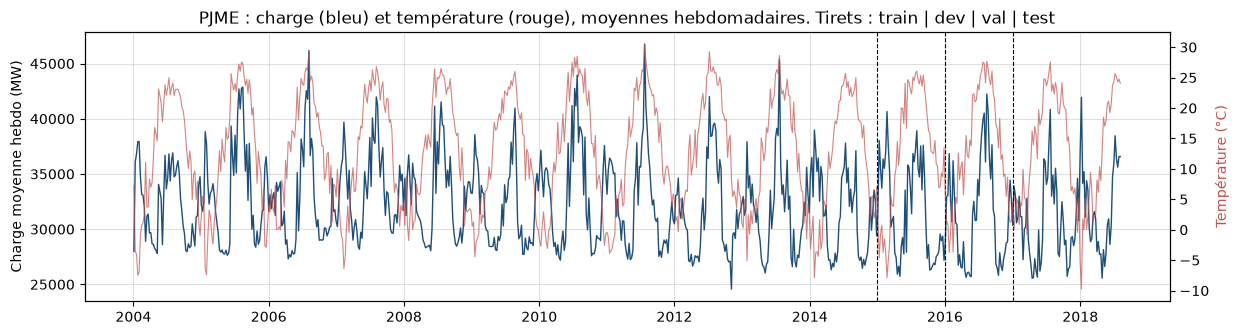

In [5]:
year = df["date"].dt.year
d_dict = {
    "train": df[year <= 2014],
    "dev": df[year == 2015],
    "val": df[year == 2016],
    "test": df[year >= 2017],
}
df_train = d_dict["train"]
display(pd.DataFrame({k: [len(v), v["date"].min(), v["date"].max()] for k, v in d_dict.items()},
                     index=["lignes", "début", "fin"]).T)

fig, ax = plt.subplots(figsize=(14, 3.5))
weekly = df.set_index("date")[[TARGET, "temp"]].resample("W").mean()
ax.plot(weekly.index, weekly[TARGET], color="#1f4e79", lw=1)
ax.set_ylabel("Charge moyenne hebdo (MW)")
ax2 = ax.twinx()
ax2.plot(weekly.index, weekly["temp"], color="#c0504d", lw=0.8, alpha=0.7)
ax2.set_ylabel("Température (°C)", color="#c0504d")
ax2.grid(False)
for start in ["2015", "2016", "2017"]:
    ax.axvline(pd.Timestamp(start), color="k", ls="--", lw=0.8)
ax.set_title("PJME : charge (bleu) et température (rouge), moyennes hebdomadaires. Tirets : train | dev | val | test")
plt.show()

### Outils communs

* `evaluate` enregistre une prévision horaire couvrant 2004-2018 dans un `BenchmarkTracker`
  et ajoute RMSE / MAPE (val, test) et le temps d'ajustement au tableau récapitulatif `RESULTS`.
* `plot_weeks` trace les prévisions sur une semaine d'hiver et une semaine d'été du test, choisies automatiquement
  autour de l'heure la plus froide (déc.-fév.) et la plus chaude (juin-août) du test.
* `predict_full` aligne les prévisions sur les dates : avec `group_col`, l'ordre des lignes renvoyé par `predict`
  suit les groupes, il ne faut donc pas se fier à `.values`.

In [6]:
RESULTS, TRACKERS, PREDS = [], {}, {}


def predict_full(model, frame=df):
    out = model.predict(frame)
    return out.set_index("date")[f"Estimated{TARGET}"].reindex(frame["date"]).to_numpy()


def fit_timed(model, method="auto_fit", quiet=True, **kwargs):
    # Ajuste sur le train et renvoie (modèle, secondes) ; quiet=True masque le journal d'auto_fit.
    buffer = StringIO()
    start = time.perf_counter()
    if quiet:
        with redirect_stdout(buffer):
            getattr(model, method)(df_train, **kwargs)
    else:
        getattr(model, method)(df_train, **kwargs)
    return model, time.perf_counter() - start


def evaluate(step, name, y_pred_full, fit_time=np.nan):
    tracker = ta.BenchmarkTracker(name)
    tracker.y_pred_full = np.asarray(y_pred_full, dtype=float)
    tracker.time_fit = fit_time
    tracker.slice_and_evaluate(d_dict, target_col=TARGET)
    TRACKERS[name], PREDS[name] = tracker, pd.Series(tracker.y_pred_full, index=df["date"])
    RESULTS[:] = [row for row in RESULTS if row["Modèle"] != name]  # ré-exécuter une cellule remplace sa ligne
    RESULTS.append({
        "Étape": step, "Modèle": name,
        "RMSE val": tracker.get_metric("val", "RMSE"), "MAPE val (%)": tracker.get_metric("val", "MAPE"),
        "RMSE test": tracker.get_metric("test", "RMSE"), "MAPE test (%)": tracker.get_metric("test", "MAPE"),
        "Temps fit (s)": fit_time,
    })
    print(f"{name:42s} | val RMSE {RESULTS[-1]['RMSE val']:7.0f}  MAPE {RESULTS[-1]['MAPE val (%)']:.2f}% "
          f"| test RMSE {RESULTS[-1]['RMSE test']:7.0f}  MAPE {RESULTS[-1]['MAPE test (%)']:.2f}% | fit {fit_time:6.1f}s")


def show_results(step=None):
    table = pd.DataFrame(RESULTS)
    if step is not None:
        table = table[table["Étape"].isin(np.atleast_1d(step))]
    return table.set_index(["Étape", "Modèle"]).style.format(
        {"RMSE val": "{:.0f}", "RMSE test": "{:.0f}", "MAPE val (%)": "{:.2f}", "MAPE test (%)": "{:.2f}", "Temps fit (s)": "{:.1f}"}
    ).highlight_min(subset=["RMSE val", "MAPE val (%)", "RMSE test", "MAPE test (%)"], color="#d9ead3")


test = d_dict["test"]
winter_peak = test.loc[test["month"].isin([12, 1, 2]), ["date", "temp"]].set_index("date")["temp"].idxmin()
summer_peak = test.loc[test["month"].isin([6, 7, 8]), ["date", "temp"]].set_index("date")["temp"].idxmax()
WEEKS = {}
for label, peak in [("hiver", winter_peak), ("été", summer_peak)]:
    start = (peak - pd.Timedelta(days=3)).normalize()
    WEEKS[f"Semaine d'{label} du test ({start:%d/%m/%Y} - {start + pd.Timedelta(days=6):%d/%m/%Y})"] = (start, start + pd.Timedelta(days=7))


def plot_weeks(names, title):
    fig, axes = plt.subplots(2, 1, figsize=(14, 8))
    truth = df.set_index("date")[TARGET]
    for ax, (label, (start, end)) in zip(axes, WEEKS.items()):
        window = slice(start, end - pd.Timedelta(hours=1))
        ax.plot(truth[window].index, truth[window], color="black", lw=2.2, label="Observé")
        for name in names:
            ax.plot(PREDS[name][window].index, PREDS[name][window], lw=1.3, label=name)
        ax.set_title(label)
        ax.set_ylabel("MW")
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d/%m"))
    axes[0].legend(loc="upper left", fontsize=9, ncol=2)
    fig.suptitle(title, fontsize=14, fontweight="bold")
    fig.tight_layout()
    plt.show()


print({k: (v[0].date(), v[1].date()) for k, v in WEEKS.items()})

{"Semaine d'hiver du test (04/01/2018 - 10/01/2018)": (datetime.date(2018, 1, 4), datetime.date(2018, 1, 11)), "Semaine d'été du test (17/07/2017 - 23/07/2017)": (datetime.date(2017, 7, 17), datetime.date(2017, 7, 24))}


## Étape 1 : modèle de base linéaire + catégoriel

**Ce que l'étape apporte.** C'est la référence : un modèle additif dont tous les effets sont soit linéaires `l()`,
soit catégoriels `c()` (un coefficient par niveau, de type *nominal*). La formule de type R
`load ~ l(x) + c(z) + ...` suffit : `StaticTAM` lit la cible et les variables directement dans le DataFrame,
construit la matrice de design, ajoute un intercept, et résout le problème pénalisé
$\min_\theta \|y - \Phi\theta\|^2 + n\,\theta^\top S(\lambda)\,\theta$ en une seule résolution exacte (problème primal).

Deux mécanismes de la bibliothèque sont examinés ici :

1. **Normalisation.** 
2. **Pénalité.** 

In [7]:
CATS = "c(tod) + c(dow) + c(month) + c(holiday)"
LAGS = "l(t) + l(load_lag24) + l(load_lag168)"
f_step1 = f"{TARGET} ~ {LAGS} + l(temp) + l(temp_s95) + l(toy) + {CATS}"
print(f_step1)

m1_default, t1_default = fit_timed(ta.StaticTAM(formula=f_step1, date_col="date"), method="fit")
evaluate(1, "1a. Linéaire, ap=-9 par défaut", predict_full(m1_default), t1_default)

load ~ l(t) + l(load_lag24) + l(load_lag168) + l(temp) + l(temp_s95) + l(toy) + c(tod) + c(dow) + c(month) + c(holiday)
1a. Linéaire, ap=-9 par défaut             | val RMSE    2413  MAPE 5.61% | test RMSE    2632  MAPE 6.32% | fit    0.3s


**La normalisation en pratique.** `norm_params_` contient, pour chaque groupe (ici un groupe factice unique, faute de
`group_col`), le min et le max d'entraînement de chaque variable. On vérifie que la valeur effectivement vue par le
modèle est bien $2\,(x - \min)/(\max - \min) - 1$. Les catégorielles sont d'abord recodées par niveau (`month` 1-12
devient 0-11), puis normalisées sur la plage des niveaux : elles ne sont pas montrées ici.

In [8]:
(group, params), = m1_default.norm_params_.items()
continuous = ["t", "load_lag24", "load_lag168", "temp", "temp_s95", "toy"]
norm_table = pd.DataFrame({"min (train)": params["min"], "max (train)": params["max"]}).loc[continuous]
row = df_train.iloc[[5000]]
norm_table["exemple brut"] = row[norm_table.index].iloc[0].values
norm_table["exemple normalisé"] = 2 * (norm_table["exemple brut"] - norm_table["min (train)"]) / (norm_table["max (train)"] - norm_table["min (train)"]) - 1
display(norm_table.round(3))
for col in ["temp", "t"]:
    lo, hi = params["min"][col], params["max"][col]
    x_test = 2 * (d_dict["test"][col] - lo) / (hi - lo) - 1
    print(f"{col:5s} normalisé sur le test : [{x_test.min():.2f}, {x_test.max():.2f}]")


,min (train),max (train),exemple brut,exemple normalisé
t,0.000,96431.000,5000.000,-0.896
load_lag24,14544.000,62009.000,31245.000,-0.296
load_lag168,14544.000,62009.000,33257.000,-0.212
temp,-21.600,39.900,20.800,0.379
temp_s95,-14.444,34.454,21.326,0.463
toy,0.000,1.000,0.569,0.139


temp  normalisé sur le test : [-1.01, 0.85]
t     normalisé sur le test : [1.36, 1.65]


**Le choix de la pénalité par GCV.** `summary()` affiche la structure du modèle et la pénalité de chaque effet
(`Reg (log10)` $= ap$). Avant `auto_fit` : tout est à -9. On lance ensuite `auto_fit` (journal affiché une fois ici) :
il renvoie le score GCV final et le $\lambda$ retenu pour chaque effet.

In [9]:
display(m1_default.summary())
m1, t1 = fit_timed(ta.StaticTAM(formula=f_step1, date_col="date"), method="auto_fit", quiet=False,
                   alpha_p_bounds=(-30.0, 6.0), number_of_steps=10, gamma=1.4)

,Feature,Type,Complexity (D),Structure / Params,Reg (log10)
0,offset,Offset,1,Global Bias,-9.0
1,t,Linear,1,Slope (Ridge),-9.0
2,load_lag24,Linear,1,Slope (Ridge),-9.0
3,load_lag168,Linear,1,Slope (Ridge),-9.0
4,temp,Linear,1,Slope (Ridge),-9.0
5,temp_s95,Linear,1,Slope (Ridge),-9.0
6,toy,Linear,1,Slope (Ridge),-9.0
7,tod,Categorical,24,"Cats=24, Topo=nominal, Unseen=edge",-9.0
8,dow,Categorical,7,"Cats=7, Topo=nominal, Unseen=edge",-9.0
9,month,Categorical,12,"Cats=12, Topo=nominal, Unseen=edge",-9.0


--- Auto-Fitting with MSP-GCV (Multiple Smoothing Parameters) ---

Final GCV Score: 5288737.6800
Optimal lambda_ps found per effect (per margin for a tensor product):
 - offset: 6.31e-17 (log10 = -16.20)
 - t: 1.58e-02 (log10 = -1.80)
 - load_lag24: 3.98e-06 (log10 = -5.40)
 - load_lag168: 3.98e-06 (log10 = -5.40)
 - temp: 1.00e+06 (log10 = 6.00)
 - temp_s95: 3.98e-06 (log10 = -5.40)
 - toy: 1.00e+06 (log10 = 6.00)
 - tod: 3.98e-06 (log10 = -5.40)
 - dow: 3.98e-06 (log10 = -5.40)
 - month: 3.98e-06 (log10 = -5.40)
 - holiday: 3.98e-06 (log10 = -5.40)


In [10]:
reg = m1_default.summary()[["Feature", "Type", "Complexity (D)"]].assign(
    **{"ap défaut": m1_default.summary()["Reg (log10)"], "ap GCV": m1.summary()["Reg (log10)"]})
display(reg)
evaluate(1, "1b. Linéaire, ap choisi par GCV", predict_full(m1), t1)
display(show_results(1))

,Feature,Type,Complexity (D),ap défaut,ap GCV
0,offset,Offset,1,-9.0,-16.2
1,t,Linear,1,-9.0,-1.8
2,load_lag24,Linear,1,-9.0,-5.4
3,load_lag168,Linear,1,-9.0,-5.4
4,temp,Linear,1,-9.0,6.0
5,temp_s95,Linear,1,-9.0,-5.4
6,toy,Linear,1,-9.0,6.0
7,tod,Categorical,24,-9.0,-5.4
8,dow,Categorical,7,-9.0,-5.4
9,month,Categorical,12,-9.0,-5.4


1b. Linéaire, ap choisi par GCV            | val RMSE    2414  MAPE 5.61% | test RMSE    2633  MAPE 6.33% | fit    0.6s


**Métriques du modèle linéaire (référence).** Le modèle `1b` (linéaire + catégoriel, pénalité choisie par GCV) sert de
point de comparaison pour la suite, car les modèles suivants sont eux aussi réglés par GCV. Le tableau donne ses
métriques sur chaque période ; `compare_to_baseline()` calcule ensuite le gain de chaque modèle par rapport à lui
(voir la synthèse).

In [11]:
BASELINE = "1b. Linéaire, ap choisi par GCV"


def baseline_metrics(name=BASELINE):
    metrics = TRACKERS[name].metrics
    table = pd.DataFrame({split: metrics[split] for split in d_dict}).T[["RMSE", "MAE", "MAPE", "R2"]]
    return table.rename(columns={"RMSE": "RMSE (MW)", "MAE": "MAE (MW)", "MAPE": "MAPE (%)"})


def compare_to_baseline(baseline=BASELINE):
    # Gain en % : positif quand le modèle fait mieux que la référence.
    columns = ["RMSE val", "MAPE val (%)", "RMSE test", "MAPE test (%)"]
    table = pd.DataFrame(RESULTS).set_index("Modèle")[columns].astype(float)
    gains = 100 * (1 - table / table.loc[baseline])
    return gains.rename(columns=lambda c: "Gain " + c.replace(" (%)", "") + " (%)")


display(baseline_metrics().style.format({"RMSE (MW)": "{:.0f}", "MAE (MW)": "{:.0f}", "MAPE (%)": "{:.2f}", "R2": "{:.3f}"}))

,RMSE (MW),MAE (MW),MAPE (%),R2
train,2298,1697,5.19,0.874
dev,2411,1802,5.60,0.866
val,2414,1784,5.61,0.873
test,2633,1988,6.33,0.815


**Lecture.**
* Le GCV pousse la pénalisation de `temp` et `toy` à la borne haute `ap = 6` : ces deux effets sont **annulés**. `l(temp)` est redondant
  avec `l(temp_s95)`, et `l(toy)` avec `c(month)` : le GCV fait de la sélection de variables.
* La tendance `t` est modérément pénalisée (`ap ≈ -2`) ; les retards et les catégorielles restent peu pénalisés
  (`ap ≈ -5`) : avec 96 000 lignes pour une cinquantaine de coefficients, l'estimation est déjà stable.
* La précision ne bouge donc quasiment pas entre 1a et 1b. L'intérêt du GCV apparaîtra quand le nombre de
  coefficients augmentera (étapes 2 et 3), et le réglage se fait sans jeu de validation.

Le modèle linéaire reste très limité (MAPE ≈ 6 % en test) : la consommation réagit à la température en **V**
(chauffage à gauche, climatisation à droite), ce qu'un terme linéaire ne peut pas représenter. Sur les semaines
ci-dessous (1a et 1b sont superposées), il sous-estime les pointes d'été et, en hiver, recopie largement la veille
(`load_lag24`) : à la fin de la vague de froid (8-9 janvier 2018) il garde un jour de retard.

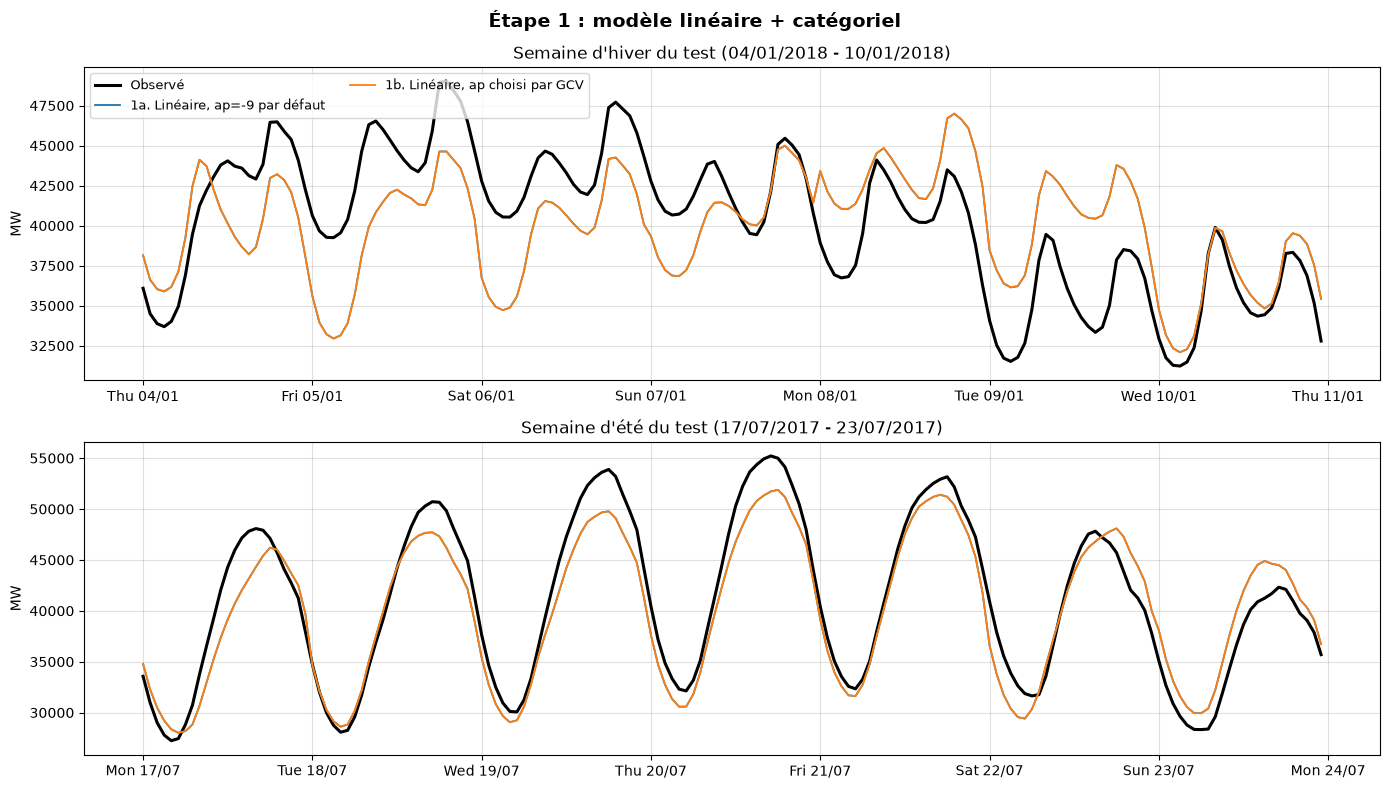

In [12]:
plot_weeks(["1a. Linéaire, ap=-9 par défaut", "1b. Linéaire, ap choisi par GCV"], "Étape 1 : modèle linéaire + catégoriel")

## Étape 2 : bases non linéaires pour la température et la saisonnalité annuelle

**Ce que l'étape apporte.** On garde la structure de l'étape 1 mais on remplace les effets linéaires de `temp`,
`temp_s95` et `toy` par des fonctions non linéaires, chacune écrite dans une base différente :

| Variante | Température (`temp`, `temp_s95`) | Saisonnalité (`toy`) | Pénalité |
|---|---|---|---|
| 2a | splines `s(x, k=20)` (B-splines cubiques, 20 nœuds) | `s(toy, k=20)` | P-spline : différences d'ordre 2 des coefficients |
| 2b | Tchebychev `p(x, deg=10, s=2)` | `p(toy, deg=10, s=2)` | Sobolev spectrale d'ordre 2 |
| 2c | Fourier non cyclique `f(x, m=8)` | Fourier **cyclique** `f(toy, m=10, cyclic=True, period=(0, 1))` | Sobolev d'ordre `s=1` |

Pour `toy`, la base de Fourier cyclique impose que la fin de l'année se raccorde au début (31 décembre ≈ 1er janvier).
`period=(0, 1)` déclare explicitement la période : sinon la plage serait le min-max du train.
Toutes les pénalités sont choisies par GCV (`auto_fit`).

In [13]:
STEP2 = {
    "2a. Splines s()": "s(temp, k=20) + s(temp_s95, k=20) + s(toy, k=20)",
    "2b. Tchebychev p()": "p(temp, deg=10, s=2) + p(temp_s95, deg=10, s=2) + p(toy, deg=10, s=2)",
    "2c. Fourier f() (toy cyclique)": "f(temp, m=8) + f(temp_s95, m=8) + f(toy, m=10, cyclic=True, period=(0, 1))",
}
models2 = {}
for name, smooth_terms in STEP2.items():
    formula = f"{TARGET} ~ {LAGS} + {smooth_terms} + {CATS}"
    models2[name], fit_time = fit_timed(ta.StaticTAM(formula=formula, date_col="date"))
    evaluate(2, name, predict_full(models2[name]), fit_time)
display(show_results([1, 2]))

2a. Splines s()                            | val RMSE    1548  MAPE 3.88% | test RMSE    1633  MAPE 4.08% | fit    1.3s
2b. Tchebychev p()                         | val RMSE    1546  MAPE 3.88% | test RMSE    1632  MAPE 4.08% | fit    0.5s
2c. Fourier f() (toy cyclique)             | val RMSE    1552  MAPE 3.88% | test RMSE    1630  MAPE 4.08% | fit    0.4s


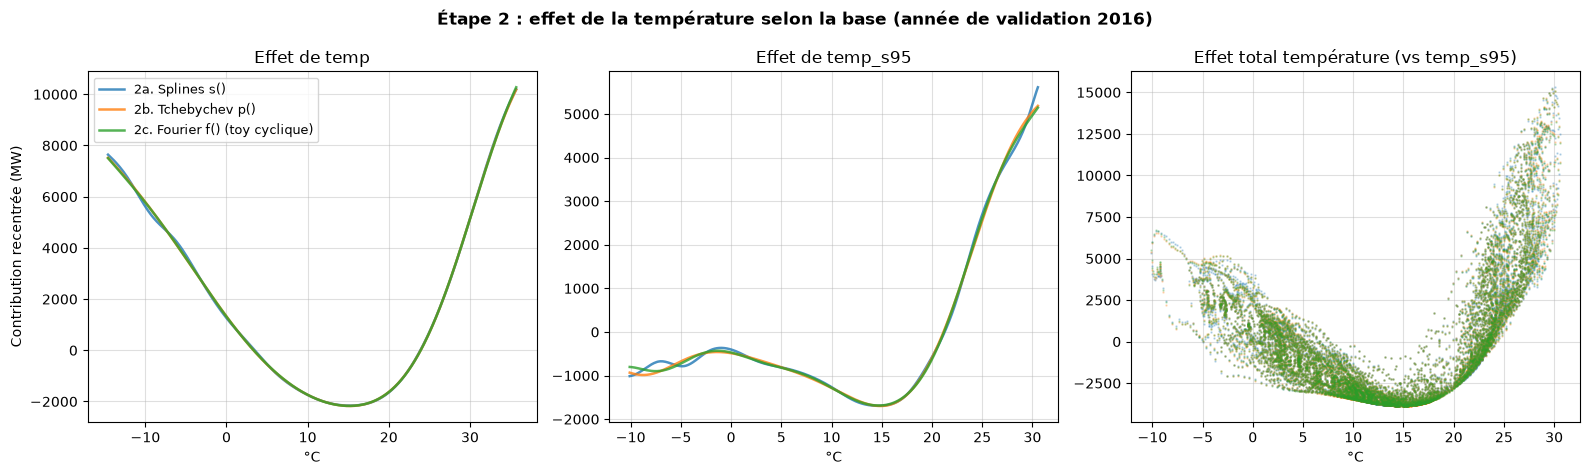

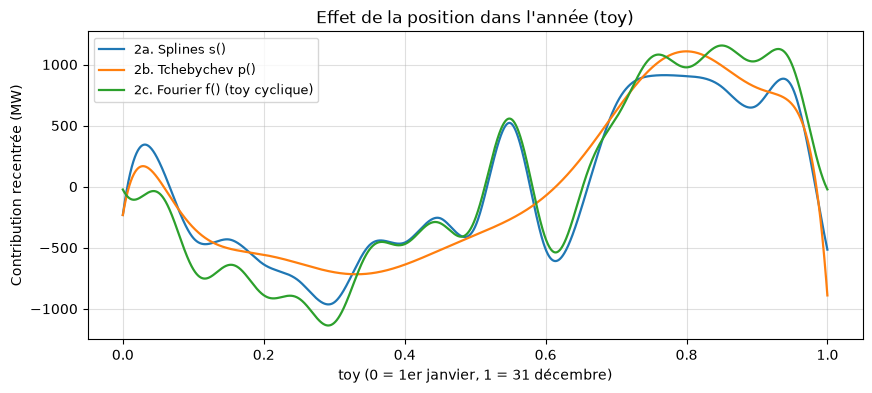

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
decomposed2 = {name: model.decompose_prediction(d_dict["val"]) for name, model in models2.items()}
for name, dec in decomposed2.items():
    dec = dec.assign(total=dec["effect_temp"] + dec["effect_temp_s95"])
    for ax, (col, x) in zip(axes, [("effect_temp", "temp"), ("effect_temp_s95", "temp_s95"), ("total", "temp_s95")]):
        curve = dec.sort_values(x)
        ax.plot(curve[x], curve[col] - curve[col].mean(), lw=1.8 if col != "total" else 0, marker="." if col == "total" else None,
                ms=1.5, alpha=0.8 if col != "total" else 0.25, label=name)
for ax, title in zip(axes, ["Effet de temp", "Effet de temp_s95", "Effet total température (vs temp_s95)"]):
    ax.set_title(title)
    ax.set_xlabel("°C")
axes[0].set_ylabel("Contribution recentrée (MW)")
axes[0].legend(fontsize=9)
fig.suptitle("Étape 2 : effet de la température selon la base (année de validation 2016)", fontweight="bold")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
for name, dec in decomposed2.items():
    curve = dec.sort_values("toy")
    ax.plot(curve["toy"], curve["effect_toy"] - curve["effect_toy"].mean(), lw=1.6, label=name)
ax.set_xlabel("toy (0 = 1er janvier, 1 = 31 décembre)")
ax.set_ylabel("Contribution recentrée (MW)")
ax.set_title("Effet de la position dans l'année (toy)")
ax.legend(fontsize=9)
plt.show()

**Remarques**
* **Précision.** Passer au non linéaire fait chuter l'erreur d'environ un tiers (RMSE val ≈ 2 400 → ≈ 1 550 MW,
  MAPE test ≈ 6,3 % → ≈ 4,1 %). Les trois bases donnent des scores quasiment identiques : avec un GCV qui règle la
  pénalité, le choix de la base compte beaucoup moins que la présence d'une non-linéarité.
* **Forme de l'effet de `temp`.** Une courbe en V asymétrique, avec un minimum vers 15 °C (zone de confort). À gauche,
  le **chauffage** : +9 000 à +10 000 MW entre 15 °C et -15 °C, soit environ 300 MW/°C. À droite, la
  **climatisation** : +12 000 MW entre 15 °C et 35 °C, soit environ 600 MW/°C, deux fois plus raide. PJME est un
  réseau à pointe estivale.
* **`temp_s95`** (mémoire d'environ 20 h) est presque plat en hiver mais monte fortement au-dessus de 20 °C : en été,
  c'est la chaleur **accumulée** (bâtiments qui ne refroidissent pas la nuit, épisodes de plusieurs jours) qui pilote
  la climatisation, au-delà de la température instantanée. Le nuage de l'effet total (à droite) montre ces deux
  composantes combinées.
* **Différences entre bases.** Au cœur des données, les trois courbes se superposent. Elles divergent aux **bords**,
  là où il y a peu de points : la spline ondule légèrement côté froid de `temp_s95`, et les pentes extrêmes au-delà de
  30 °C diffèrent. C'est là que le comportement en extrapolation propre à chaque base compte (`extrapolate='linear'`
  par défaut pour `s()`, `'saturation'` pour `p()`, prolongement périodique pour `f()`).
* **Effet de `toy`.** Tchebychev (degré 10, pénalité de Sobolev) donne une saisonnalité très lisse. Splines et
  Fourier captent des motifs plus courts, comme une bosse mi-juillet et un creux mi-août (probablement les congés).
  Seule la base de **Fourier cyclique** raccorde exactement le 31 décembre au 1er janvier ; les deux autres ont des
  extrémités libres. Une partie de cet effet est partagée avec `c(month)`, ce qui explique son amplitude modeste
  (± 1 000 MW).

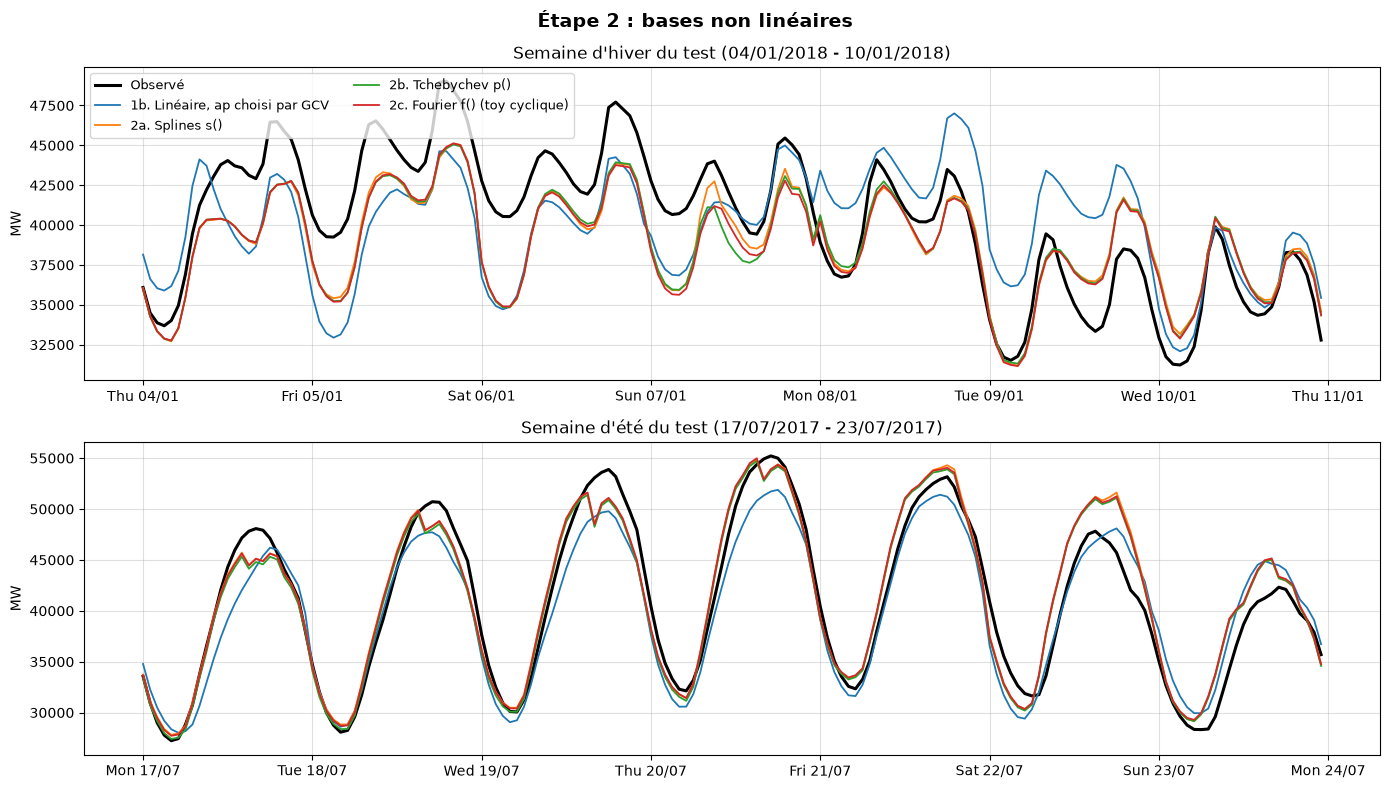

In [15]:
plot_weeks(["1b. Linéaire, ap choisi par GCV"] + list(STEP2), "Étape 2 : bases non linéaires")

## Étape 3 : interaction température × heure, puis un modèle par heure

**Ce que l'étape apporte.** L'effet de la température dépend de l'heure : un coup de froid pèse surtout au réveil et
en soirée, la chaleur surtout l'après-midi. Deux façons de le représenter :

* **3a. Produit tensoriel `te()`** : on ajoute `te(s(temp, k=10), c(tod, n_cat=24))` au meilleur modèle de
  l'étape 2, c'est-à-dire une courbe de température par heure. La pénalité de `te` est une somme de Kronecker
  (lissage selon chaque marge) ; le GCV choisit un $\lambda$ par marge.
* **3b. Un modèle par heure avec `group_col='tod'`** (Pierrot & Goude, 2011) : *tous* les coefficients deviennent
  propres à l'heure (effet des retards, du jour de la semaine, de la température...). `StaticTAM` empile les 24
  sous-problèmes dans un tenseur `(24, n, p)` et les résout en un seul appel batché, au lieu d'une boucle Python.
  La normalisation est elle aussi faite par heure (`norm_params_` a 24 entrées). `c(tod)` disparaît de la formule
  (constant dans chaque groupe). La pénalité choisie par GCV est commune aux 24 modèles.

In [16]:
best2 = min(STEP2, key=lambda n: next(r["RMSE val"] for r in RESULTS if r["Modèle"] == n))
smooth2 = STEP2[best2]
print("Meilleur modèle de l'étape 2 (RMSE val) :", best2)

f_te = f"{TARGET} ~ {LAGS} + {smooth2} + te(s(temp, k=10), c(tod, n_cat=24)) + {CATS}"
m3_te, t3_te = fit_timed(ta.StaticTAM(formula=f_te, date_col="date"))
evaluate(3, "3a. Étape 2 + te(temp, tod)", predict_full(m3_te), t3_te)

f_group = f"{TARGET} ~ {LAGS} + {smooth2} + c(dow) + c(month) + c(holiday)"
m3_grp, t3_grp = fit_timed(ta.StaticTAM(formula=f_group, date_col="date", group_col="tod"))
evaluate(3, "3b. 24 modèles horaires (group_col='tod')", predict_full(m3_grp), t3_grp)
print(f"\nGroupes ajustés : {len(m3_grp.unique_groups_)}, coefficients : {tuple(m3_grp.coefficients_.shape)}  (groupes, coefficients, 1)")
display(show_results([2, 3]))

Meilleur modèle de l'étape 2 (RMSE val) : 2b. Tchebychev p()
3a. Étape 2 + te(temp, tod)                | val RMSE    1475  MAPE 3.70% | test RMSE    1560  MAPE 3.88% | fit    3.4s
3b. 24 modèles horaires (group_col='tod')  | val RMSE    1238  MAPE 2.87% | test RMSE    1339  MAPE 3.10% | fit    0.8s

Groupes ajustés : 24, coefficients : (24, 55, 1)  (groupes, coefficients, 1)


**Effet de la température selon l'heure.** À gauche, la composante `te` du modèle 3a (somme de l'effet principal
`temp` et de l'interaction) ; à droite, l'effet de `temp` dans chacun des 24 modèles du 3b. Quelques heures
seulement sont tracées pour la lisibilité.

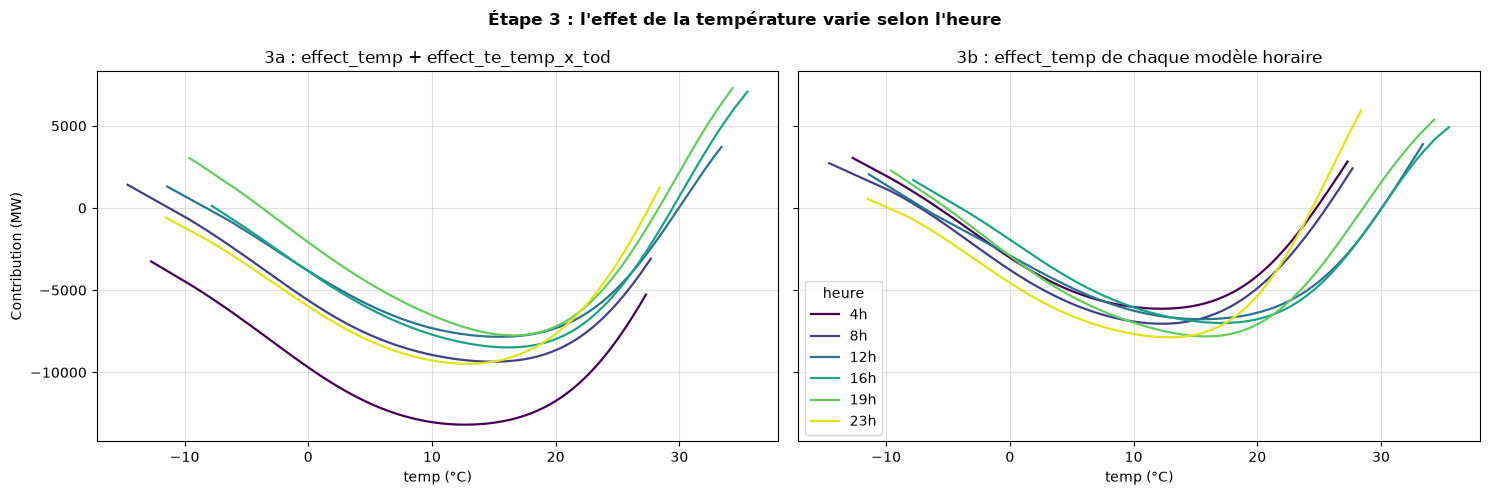

In [17]:
HOURS = [4, 8, 12, 16, 19, 23]
colors = plt.cm.viridis(np.linspace(0, 0.95, len(HOURS)))
dec_te = m3_te.decompose_prediction(d_dict["val"])
te_col = next(c for c in dec_te.columns if c.startswith("effect_te_"))
dec_grp = m3_grp.decompose_prediction(d_dict["val"])
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for hour, color in zip(HOURS, colors):
    part = dec_te[dec_te["tod"] == hour].sort_values("temp")
    axes[0].plot(part["temp"], part["effect_temp"] + part[te_col], color=color, lw=1.6, label=f"{hour}h")
    part = dec_grp[dec_grp["tod"] == hour].sort_values("temp")
    axes[1].plot(part["temp"], part["effect_temp"], color=color, lw=1.6, label=f"{hour}h")
axes[0].set_title(f"3a : effect_temp + {te_col}")
axes[1].set_title("3b : effect_temp de chaque modèle horaire")
for ax in axes:
    ax.set_xlabel("temp (°C)")
axes[0].set_ylabel("Contribution (MW)")
axes[1].legend(title="heure")
fig.suptitle("Étape 3 : l'effet de la température varie selon l'heure", fontweight="bold")
fig.tight_layout()
plt.show()

**Commentaire.**
* **3a (`te`)** : gain modéré (RMSE val ≈ 1 550 → ≈ 1 475 MW). Les courbes changent de forme selon l'heure :
  la nuit (4 h) la climatisation pèse peu et la courbe remonte tard, alors qu'en fin d'après-midi (16-19 h) la pente
  chaude est la plus forte. Les niveaux des courbes ne sont pas à comparer : le décalage moyen par heure se répartit
  librement entre `c(tod)` et `te`, seule la forme est identifiable.
* **3b (`group_col='tod'`)** : c'est le saut le plus important de tout le notebook (RMSE val ≈ 1 240 MW, MAPE test
  ≈ 3,1 %). Au-delà de la température, *tous* les effets deviennent horaires : le poids de `load_lag24` (la veille est
  un bien meilleur prédicteur à 3 h du matin qu'à 18 h), l'effet du week-end, des jours fériés, de la saison...
  On retrouve dans les courbes de droite un minimum qui se décale avec l'heure (plus froid la nuit, plus chaud
  l'après-midi).
* **Temps de calcul** : malgré ses 24 jeux de coefficients, 3b s'ajuste (GCV compris) aussi vite que les modèles de
  l'étape 2, et plus vite que 3a. Les 24 systèmes, de petite taille (55 coefficients chacun), sont résolus en un seul
  appel batché, alors que 3a résout un seul système plus gros (plus de 300 colonnes de plus) avec un $\lambda$
  supplémentaire à régler.
* Sur la semaine de froid extrême de janvier 2018 (-15 °C), tous les modèles sous-estiment encore la pointe de plusieurs
  milliers de MW : ces températures sont aux bords du domaine d'apprentissage.

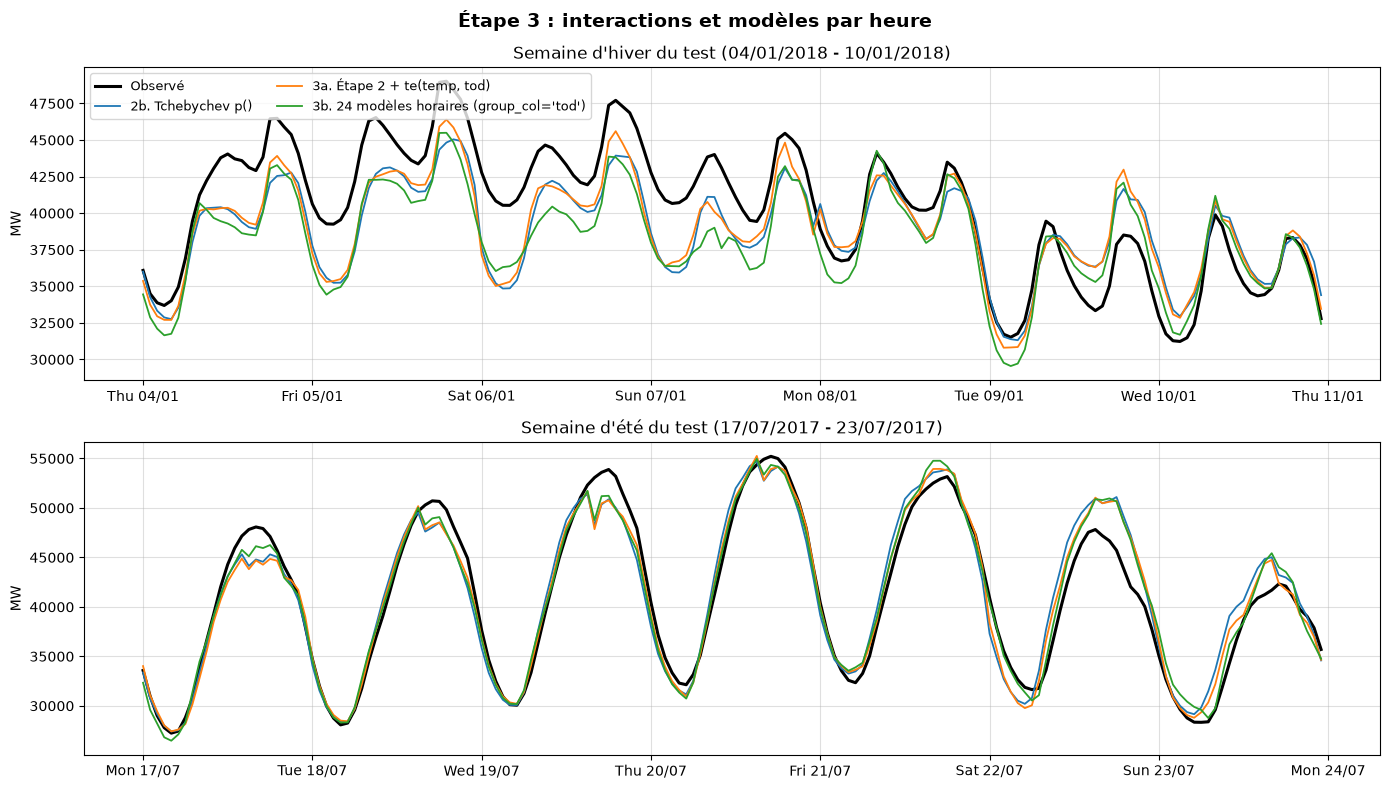

In [18]:
plot_weeks([best2, "3a. Étape 2 + te(temp, tod)", "3b. 24 modèles horaires (group_col='tod')"], "Étape 3 : interactions et modèles par heure")

## Étape 4 : adaptation à la dérive avec `AdaptiveTAM`

**Ce que l'étape apporte.** Un modèle statique est figé à fin 2014 : toute évolution ultérieure (croissance ou
baisse de la demande, changements d'usages, périmètre de la zone) se retrouve dans les résidus, qui restent
fortement autocorrélés. `AdaptiveTAM` ajoute au modèle de base un **second modèle, ajusté sur ses résidus** et
**ré-estimé en continu sur une fenêtre glissante** :

* cible : `Residualload` $= y - \hat y_{\text{base}}$, calculée en interne ;
* variables : ici le résidu de la veille à la même heure `L_Res` (résidu décalé, comme dans `cheatsheet.py`) plus un
  intercept : la correction apprend à la fois un biais local et la persistance des erreurs ;
* `predict_online` simule l'exploitation réelle : chaque jour, on réajuste sur les `training_window_periods`
  derniers jours connus et on corrige le jour suivant (`update_interval_periods=1`, `horizon_steps=1` :
  aucune information du jour prévu n'est utilisée).

Le modèle de base est le meilleur de l'étape 3. S'il est groupé par heure, `AdaptiveTAM` hérite de `group_col='tod'` :
chaque heure a sa propre correction, et une *période* vaut une ligne du groupe, soit un jour (`steps_per_period=1`).
La simulation démarre au 1er janvier 2015 (dev), si bien que la fenêtre est déjà remplie au début de val.
On compare deux tailles de fenêtre : **28 jours** (réactive) et **365 jours** (stable).

In [19]:
best3 = min(["3a. Étape 2 + te(temp, tod)", "3b. 24 modèles horaires (group_col='tod')"],
            key=lambda n: next(r["RMSE val"] for r in RESULTS if r["Modèle"] == n))
base_model = {"3a. Étape 2 + te(temp, tod)": m3_te, "3b. 24 modèles horaires (group_col='tod')": m3_grp}[best3]
grouped = base_model.group_col_ == "tod"
print("Modèle de base :", best3, "| groupé par heure :", grouped)

# Résidu de la veille à la même heure (disponible au moment de prévoir J).
df["L_Res"] = (df[TARGET] - PREDS[best3].to_numpy()).shift(24).bfill()
online = df[df["date"] >= "2015-01-01"].copy()

adaptive = {}
for days in [28, 365]:
    name = f"4. {best3[:3]} + AdaptiveTAM {days} j"
    model = ta.AdaptiveTAM(
        base_model=base_model,
        adaptive_formula=f"Residual{TARGET} ~ l(L_Res)",
        update_interval_periods=1,
        training_window_periods=days,
        steps_per_period=1 if grouped else 24,
        horizon_steps=1 if grouped else 24,
    )
    start = time.perf_counter()
    out = model.predict_online(online)
    elapsed = time.perf_counter() - start
    adapted = out.set_index("date")[f"AdaptedEstimated{TARGET}"].reindex(df["date"])
    full = PREDS[best3].copy()  # avant 2015 : prévision de base (pas de correction)
    full.loc[adapted.dropna().index] = adapted.dropna()
    evaluate(4, name, full.to_numpy(), elapsed)
    adaptive[days] = name
display(show_results([3, 4]))

Modèle de base : 3b. 24 modèles horaires (group_col='tod') | groupé par heure : True
4. 3b. + AdaptiveTAM 28 j                  | val RMSE    1198  MAPE 2.62% | test RMSE    1260  MAPE 2.91% | fit    0.5s
4. 3b. + AdaptiveTAM 365 j                 | val RMSE    1167  MAPE 2.54% | test RMSE    1271  MAPE 2.90% | fit    0.7s


**Évolution de l'erreur dans le temps.** RMSE glissante sur 30 jours (calculée chaque jour) sur val + test, avant et
après adaptation, puis le biais mensuel (erreur moyenne) qui montre la dérive que la correction absorbe.

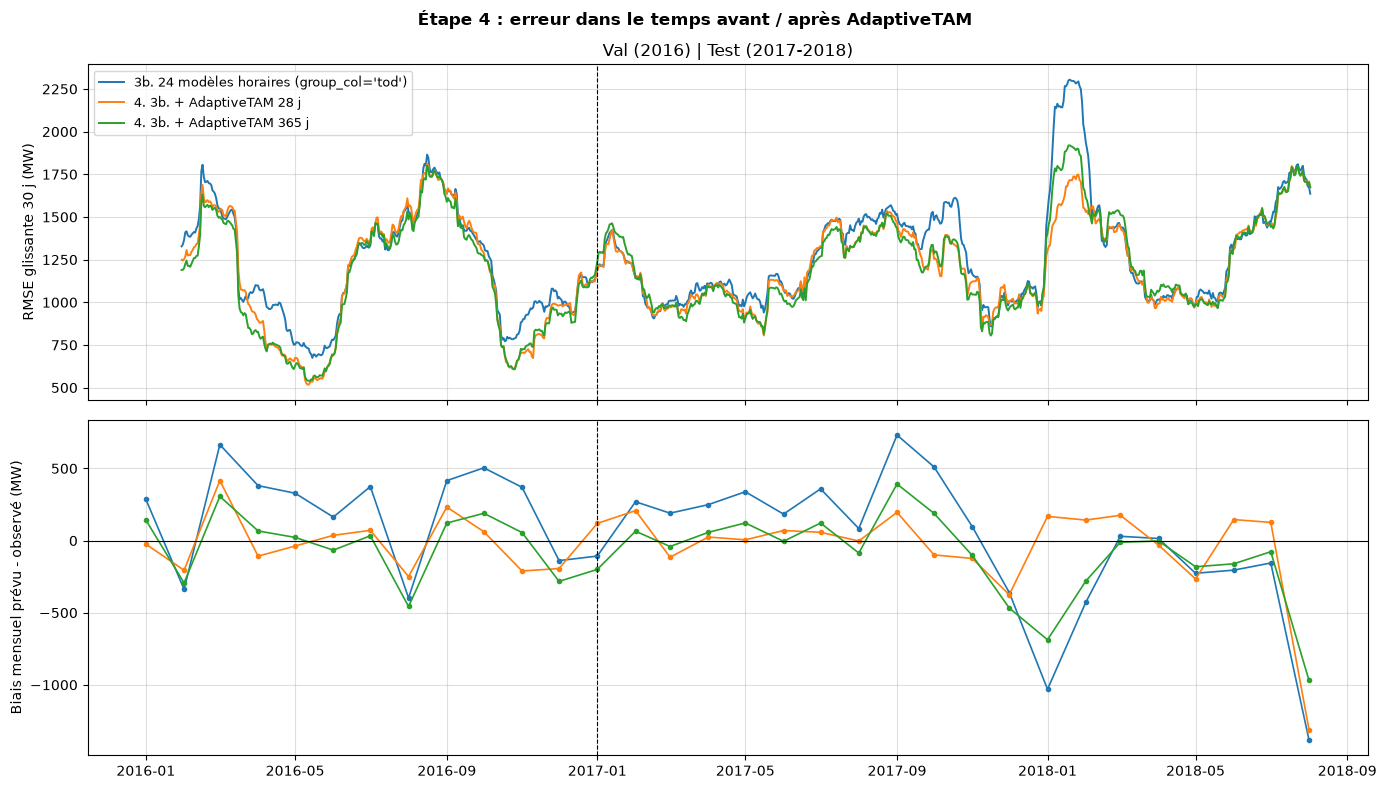

In [20]:
truth = df.set_index("date")[TARGET]
span = slice("2016-01-01", None)
names4 = [best3] + list(adaptive.values())
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for name in names4:
    err = (truth - PREDS[name])[span]
    rolling_rmse = np.sqrt((err ** 2).resample("D").mean().rolling(30).mean())
    axes[0].plot(rolling_rmse.index, rolling_rmse, lw=1.4, label=name)
    monthly_bias = (-err).resample("MS").mean()
    axes[1].plot(monthly_bias.index, monthly_bias, marker="o", ms=3, lw=1.2, label=name)
axes[0].set_ylabel("RMSE glissante 30 j (MW)")
axes[1].set_ylabel("Biais mensuel prévu - observé (MW)")
axes[1].axhline(0, color="k", lw=0.8)
for ax in axes:
    ax.axvline(pd.Timestamp("2017-01-01"), color="k", ls="--", lw=0.8)
axes[0].legend(fontsize=9)
axes[0].set_title("Val (2016) | Test (2017-2018)")
fig.suptitle("Étape 4 : erreur dans le temps avant / après AdaptiveTAM", fontweight="bold")
fig.tight_layout()
plt.show()

**Commentaire.**
* **Gain global** : les deux fenêtres améliorent le modèle de base sur val et sur test (environ -5 % de RMSE
  sur le test), pour un surcoût de calcul inférieur à la seconde : les milliers de petites régressions glissantes
  (une par jour et par heure) sont elles aussi résolues par lots.
* **Dérive** : le modèle statique a un **biais positif persistant** (il surestime la charge de plusieurs centaines de
  MW la plupart des mois de 2016-2017). La tendance `l(t)` apprise sur 2004-2014 ne colle plus à une demande devenue
  plus plate. La correction en ligne ramène le biais mensuel autour de zéro. À l'inverse, pendant l'hiver 2017-2018
  le modèle de base sous-estime (biais d'environ -1 000 MW en janvier) ; la fenêtre de 28 jours le corrige presque
  entièrement. Le dernier point (août 2018) ne couvre que deux journées.
* **Taille de fenêtre** : la fenêtre de **28 jours** est plus réactive. Lors de la vague de froid de janvier 2018,
  le pic de RMSE glissante baisse nettement plus qu'avec 365 jours, car elle « oublie » vite et suit les erreurs
  persistantes d'un épisode. La fenêtre de **365 jours** estime une correction plus stable, moins bruitée par les
  épisodes courts, et l'emporte sur val. C'est le compromis classique biais / variance de l'adaptation.
  Les deux variantes sont complémentaires, ce qui invite à les agréger (voir la conclusion).

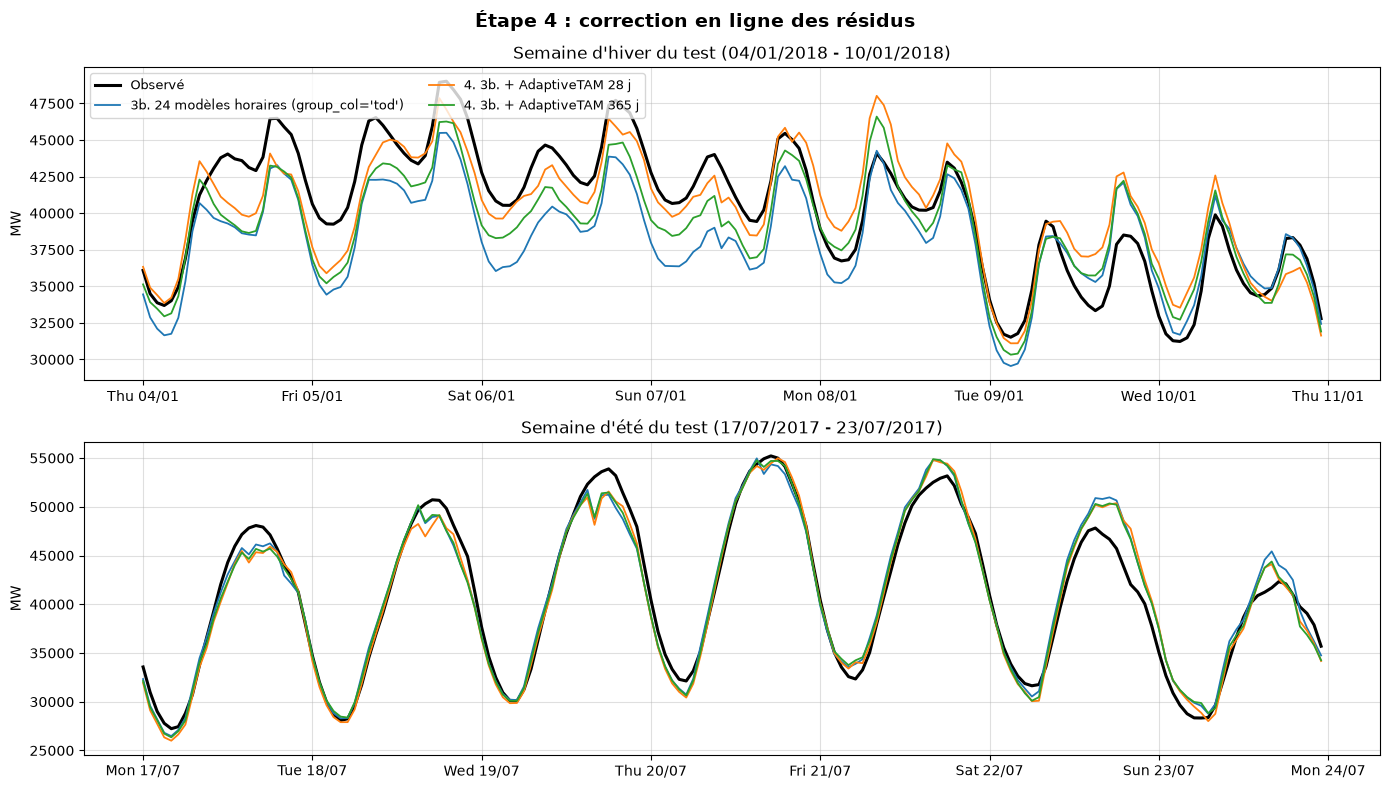

In [21]:
plot_weeks(names4, "Étape 4 : correction en ligne des résidus")

## Synthèse

Tableau récapitulatif de toutes les étapes (meilleure valeur de chaque colonne surlignée), gain de chaque modèle
par rapport au modèle linéaire de référence, puis le tableau de bord
de la bibliothèque (`plot_benchmark_dashboard`, utilisé par `use_cases/utils_cases.show_trackers_plot`) sur une
sélection de modèles.

In [22]:
display(show_results())

In [23]:
display(compare_to_baseline().style.format("{:+.1f}"))

,Gain RMSE val (%),Gain MAPE val (%),Gain RMSE test (%),Gain MAPE test (%)
Modèle,,,,
"1a. Linéaire, ap=-9 par défaut",+0.0,+0.1,+0.0,+0.0
"1b. Linéaire, ap choisi par GCV",+0.0,+0.0,+0.0,+0.0
2a. Splines s(),+35.9,+30.9,+38.0,+35.4
2b. Tchebychev p(),+35.9,+30.9,+38.0,+35.5
2c. Fourier f() (toy cyclique),+35.7,+30.8,+38.1,+35.5
"3a. Étape 2 + te(temp, tod)",+38.9,+34.0,+40.8,+38.7
3b. 24 modèles horaires (group_col='tod'),+48.7,+48.9,+49.1,+51.0
4. 3b. + AdaptiveTAM 28 j,+50.4,+53.2,+52.1,+54.0
4. 3b. + AdaptiveTAM 365 j,+51.7,+54.8,+51.7,+54.1


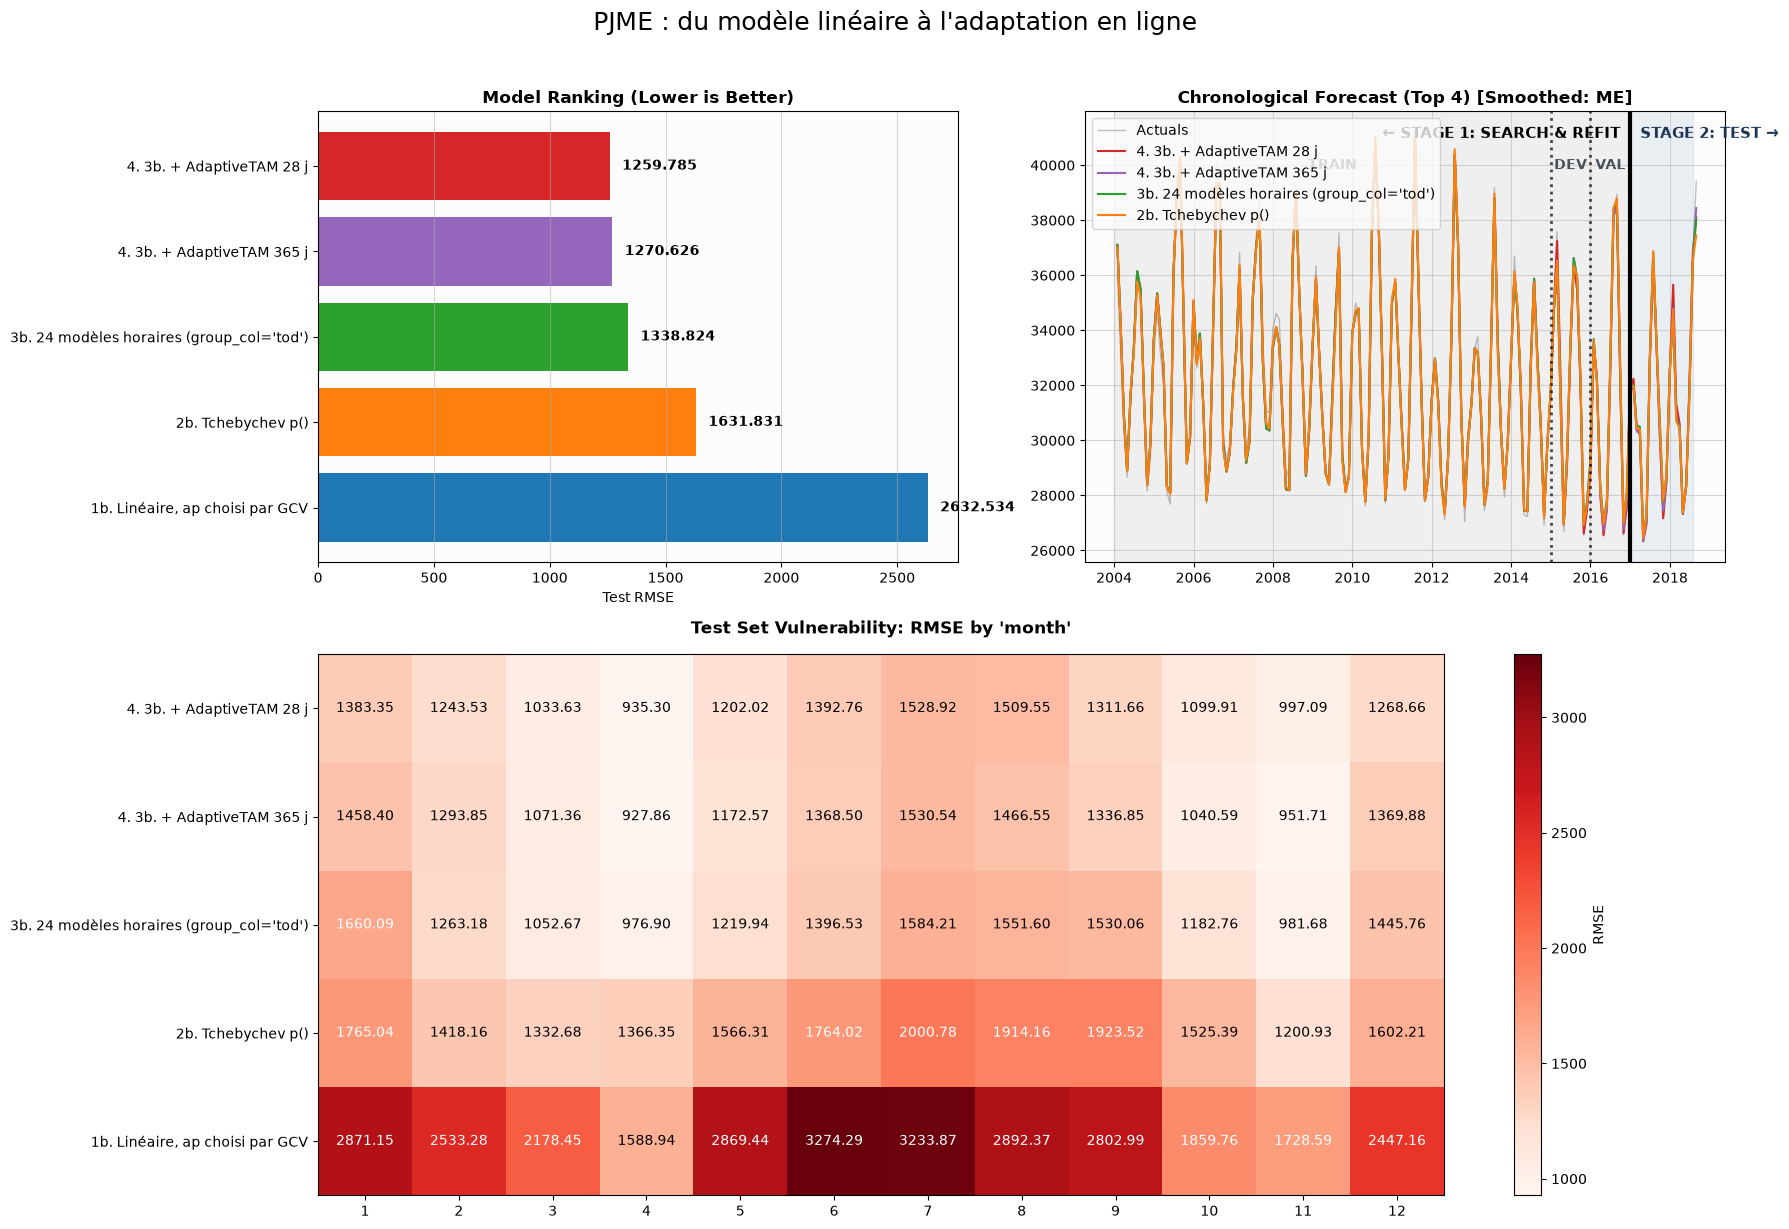

In [24]:
from tam.evaluation.eval_plotting import plot_benchmark_dashboard

selection = ["1b. Linéaire, ap choisi par GCV", best2, best3] + list(adaptive.values())
plot_benchmark_dashboard(
    data_dict=d_dict, trackers_dict={n: TRACKERS[n] for n in selection}, target_col=TARGET, date_col="date",
    is_timeseries=True, primary_metric="RMSE", title="PJME : du modèle linéaire à l'adaptation en ligne",
    heatmap_col="month", forecast_smoothing="ME",
)

**Conclusion.** En quatre étapes, la MAPE de test passe d'environ 6,3 % à environ 2,9 % :

1. le modèle linéaire + catégoriel pose la référence et montre la mécanique de `StaticTAM` (formule, normalisation
   min-max, pénalité `ap`, GCV qui sélectionne les effets) ;
2. les bases non linéaires (`s`, `p`, `f`) capturent la réponse en V à la température, qui est le gain principal ;
   le choix précis de la base compte peu une fois la pénalité réglée par GCV ;
3. un modèle par heure (`group_col='tod'`) est le second gain majeur, à coût de calcul nul grâce au batch ;
4. `AdaptiveTAM` corrige la dérive post-apprentissage et les épisodes persistants.


In [25]:
# Températures max et min de la journée (même valeur pour les 24 heures du jour)
day = df["date"].dt.normalize()
df["temp_max"] = df.groupby(day)["temp"].transform("max")
df["temp_min"] = df.groupby(day)["temp"].transform("min")

# d_dict et df_train sont des copies de df : on les reconstruit pour qu'ils voient les nouvelles colonnes
year = df["date"].dt.year
d_dict = {"train": df[year <= 2014], "dev": df[year == 2015], "val": df[year == 2016], "test": df[year >= 2017]}
df_train = d_dict["train"]


In [26]:
TMM = "p(temp_max, deg=10, s=2) + p(temp_min, deg=10, s=2)"
f5 = f"{TARGET} ~ {LAGS} + {smooth2} + {TMM} + c(dow) + c(month) + c(holiday)"
m5, t5 = fit_timed(ta.StaticTAM(formula=f5, date_col="date", group_col="tod"))
evaluate(5, "5a. 3b + temp max/min du jour", predict_full(m5), t5)


5a. 3b + temp max/min du jour              | val RMSE    1124  MAPE 2.64% | test RMSE    1219  MAPE 2.85% | fit    0.9s


In [27]:
BASE5 = "5a. 3b + temp max/min du jour"
df["L_Res5"] = (df[TARGET] - PREDS[BASE5].to_numpy()).shift(24).bfill()
online5 = df[df["date"] >= "2015-01-01"].copy()

for add_base in [False, True]:
    model = ta.AdaptiveTAM(
        base_model=m5,
        adaptive_formula=f"Residual{TARGET} ~ l(L_Res5)",
        update_interval_periods=1,
        training_window_periods=365,
        steps_per_period=1,
        horizon_steps=1,
        add_base_effects=add_base,  # True : ré-estime aussi le poids de chaque effet du modèle de base sur la fenêtre
    )
    start = time.perf_counter()
    out = model.predict_online(online5)
    elapsed = time.perf_counter() - start
    adapted = out.set_index("date")[f"AdaptedEstimated{TARGET}"].reindex(df["date"])
    full = PREDS[BASE5].copy()
    full.loc[adapted.dropna().index] = adapted.dropna()
    evaluate(5, "5b. 5a + AdaptiveTAM 365 j" + (" + add_base_effects" if add_base else ""), full.to_numpy(), elapsed)

display(show_results([3, 4, 5]))
display(compare_to_baseline().style.format("{:+.1f}"))


5b. 5a + AdaptiveTAM 365 j                 | val RMSE    1086  MAPE 2.42% | test RMSE    1199  MAPE 2.76% | fit    0.7s
5b. 5a + AdaptiveTAM 365 j + add_base_effects | val RMSE    1050  MAPE 2.31% | test RMSE    1121  MAPE 2.57% | fit    4.2s


,Gain RMSE val (%),Gain MAPE val (%),Gain RMSE test (%),Gain MAPE test (%)
Modèle,,,,
"1a. Linéaire, ap=-9 par défaut",+0.0,+0.1,+0.0,+0.0
"1b. Linéaire, ap choisi par GCV",+0.0,+0.0,+0.0,+0.0
2a. Splines s(),+35.9,+30.9,+38.0,+35.4
2b. Tchebychev p(),+35.9,+30.9,+38.0,+35.5
2c. Fourier f() (toy cyclique),+35.7,+30.8,+38.1,+35.5
"3a. Étape 2 + te(temp, tod)",+38.9,+34.0,+40.8,+38.7
3b. 24 modèles horaires (group_col='tod'),+48.7,+48.9,+49.1,+51.0
4. 3b. + AdaptiveTAM 28 j,+50.4,+53.2,+52.1,+54.0
4. 3b. + AdaptiveTAM 365 j,+51.7,+54.8,+51.7,+54.1


## Comparison with R mgcv:

We do here a little comparison with the R suite mgcv, that solves the same penalized regression problem, having similar metrics is a good validation of our model.

In [ ]:
import shutil, subprocess, tempfile
from glob import glob

rscript = shutil.which("Rscript") or max(glob("C:/Program Files/R/R-*/bin/Rscript.exe"), default=None)
if rscript is None:
    raise RuntimeError("Rscript introuvable : installer R (mgcv est inclus) puis redémarrer VS Code.")

R_SCRIPT = r"""
args <- commandArgs(trailingOnly = TRUE)
suppressMessages(library(mgcv))
d <- read.csv(args[1])
d$dow <- factor(d$dow); d$month <- factor(d$month); d$holiday <- factor(d$holiday)
train <- d$year <= 2014
form <- load ~ t + load_lag24 + load_lag168 +
  s(temp, k = 11) + s(temp_s95, k = 11) + s(toy, k = 11) + s(temp_max, k = 11) + s(temp_min, k = 11) +
  dow + month + holiday
d$pred <- NA_real_
fit_time <- 0
for (h in 0:23) {                      # un modèle par heure, comme group_col='tod'
  rows <- d$tod == h
  t0 <- proc.time()[["elapsed"]]
  m <- gam(form, data = d[rows & train, ], method = "GCV.Cp", gamma = 1.4)
  fit_time <- fit_time + proc.time()[["elapsed"]] - t0
  d$pred[rows] <- predict(m, newdata = d[rows, ])
}
write.csv(data.frame(date = d$date, pred = d$pred), args[2], row.names = FALSE)
cat(fit_time, file = args[3])
"""

cols = ["date", "tod", TARGET, "t", "load_lag24", "load_lag168", "temp", "temp_s95", "toy",
        "temp_max", "temp_min", "dow", "month", "holiday"]
with tempfile.TemporaryDirectory() as tmp:
    tmp = Path(tmp)
    (tmp / "fit.R").write_text(R_SCRIPT, encoding="utf-8")
    df[cols].assign(year=df["date"].dt.year).to_csv(tmp / "data.csv", index=False)
    run = subprocess.run([rscript, tmp / "fit.R", tmp / "data.csv", tmp / "pred.csv", tmp / "time.txt"],
                         capture_output=True, text=True)
    if run.returncode != 0:
        raise RuntimeError(run.stderr)
    pred_mgcv = pd.read_csv(tmp / "pred.csv", parse_dates=["date"]).set_index("date")["pred"].reindex(df["date"]).to_numpy()
    fit_mgcv = float((tmp / "time.txt").read_text())

evaluate(6, "6. mgcv : 24 gam(), GCV gamma=1.4", pred_mgcv, fit_mgcv)
display(show_results([5, 6]))


6. mgcv : 24 gam(), GCV gamma=1.4          | val RMSE    1124  MAPE 2.65% | test RMSE    1216  MAPE 2.86% | fit    7.0s
